# Natural Language Processing (Assignment 2)
##### Saba Firdous (25L-8006)

# Part 1: Advanced Smoothing — Good-Turing and Kneser-Ney

## Imports and Corpus Downloads

In [35]:

import math
import random
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from nltk.corpus import brown, gutenberg, webtext, stopwords
import numpy as np
from sklearn.datasets import fetch_20newsgroups

from sklearn.metrics import ( 
  accuracy_score, 
  classification_report, 
  confusion_matrix, 
  f1_score, 
  precision_score, 
  recall_score, )
import ssl
import nltk
import re

# Bypass the macOS SSL certificate check
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

# List of required NLTK data dependencies
REQUIRED_nltk = [
    'brown',  # For Part 1 Train/Test & Part 2 OOV
    'webtext',  # For Part 1 Out-of-Domain Test
    'gutenberg',  # For Part 2 OOV Test
    'stopwords',  # For Part 2 Naive Bayes
    'punkt',  # Tokenization
    'punkt_tab',  # Extended Punkt tables
]

for resource in REQUIRED_nltk:
  nltk.download(resource, quiet=True)

print("All NLTK corpora cached successfully.")


All NLTK corpora cached successfully.


### **Step 1: Task P1T1 — Corpus Preparation & Baseline Bigram Model**


In [36]:
# 1. Corpus Preprocessing Function
def preprocess_sentences(sents):
  """Lowercases tokens and adds sentence boundary markers <s> and </s>."""
  processed = []
  for sent in sents:
    tokens = ['<s>'] + [w.lower() for w in sent] + ['</s>']
    processed.append(tokens)
  return processed

# Load Training and Test Corpora
train_sents = preprocess_sentences(
    brown.sents(categories=['learned', 'government'])
)
test_indomain_sents = preprocess_sentences(brown.sents(categories=['reviews']))
test_outdomain_sents = preprocess_sentences(webtext.sents())

### **2. Report: total number of sentences, total tokens (including markers), vocabulary size (unique word types)**

In [37]:
# Compute Training Corpus Statistics
train_tokens = [w for sent in train_sents for w in sent]
N_tokens = len(train_tokens)
vocab = set(train_tokens)
V = len(vocab)
num_sents = len(train_sents)

print("TRAINING CORPUS STATISTICS")
print(f"Total Sentences : {num_sents}")
print(f"Total Tokens    : {N_tokens}")
print(f"Vocabulary Size : {V}\n")

TRAINING CORPUS STATISTICS
Total Sentences : 10766
Total Tokens    : 273537
Vocabulary Size : 18038



### **3. Train the following three baseline bigram models:**
(a) Unsmoothed bigram model  
(b) Laplace (add-one) smoothed bigram model  
(c) Laplace smoothed unigram model (for backoff reference)  

In [38]:
# Frequency Counting
unigram_counts = Counter(train_tokens)
bigram_counts = Counter()
for sent in train_sents:
  for i in range(len(sent) - 1):
    bigram_counts[(sent[i], sent[i + 1])] += 1

# 2. Baseline Model Classes
class UnsmoothedBigramModel:

  def __init__(self, uni_counts, bi_counts):
    self.uni_counts = uni_counts
    self.bi_counts = bi_counts

  def get_prob(self, w_prev, w_curr):
    c_prev = self.uni_counts[w_prev]
    if c_prev == 0:
      return 0.0
    return self.bi_counts[(w_prev, w_curr)] / c_prev

  def generate_sentence(self):
    sent = ['<s>']
    curr = '<s>'
    while curr != '</s>':
      # Filter candidates with P > 0
      candidates = [
          w2
          for (w1, w2), count in self.bi_counts.items()
          if w1 == curr and count > 0
      ]
      if not candidates:
        break
      probs = [self.get_prob(curr, w) for w in candidates]
      total = sum(probs)
      norm_probs = [p / total for p in probs]
      curr = random.choices(candidates, weights=norm_probs)[0]
      sent.append(curr)
      if len(sent) > 50:  # Safety cap
        sent.append('</s>')
        break
    return sent

class LaplaceSmoothedBigramModel:

  def __init__(self, uni_counts, bi_counts, V):
    self.uni_counts = uni_counts
    self.bi_counts = bi_counts
    self.V = V

  def get_prob(self, w_prev, w_curr):
    return (self.bi_counts[(w_prev, w_curr)] + 1) / (
        self.uni_counts[w_prev] + self.V
    )

  def generate_sentence(self):
    vocab_list = list(self.uni_counts.keys())
    sent = ['<s>']
    curr = '<s>'
    while curr != '</s>':
      probs = [self.get_prob(curr, w) for w in vocab_list]
      curr = random.choices(vocab_list, weights=probs)[0]
      sent.append(curr)
      if len(sent) > 50:
        sent.append('</s>')
        break
    return sent

class LaplaceSmoothedUnigramModel:

  def __init__(self, uni_counts, N, V):
    self.uni_counts = uni_counts
    self.N = N
    self.V = V

  def get_prob(self, word):
    return (self.uni_counts[word] + 1) / (self.N + self.V)

  def generate_sentence(self):
    vocab_list = list(self.uni_counts.keys())
    probs = [self.get_prob(w) for w in vocab_list]
    sent = ['<s>']
    curr = ''
    while curr != '</s>':
      curr = random.choices(vocab_list, weights=probs)[0]
      if curr != '<s>':
        sent.append(curr)
      if len(sent) > 50:
        sent.append('</s>')
        break
    return sent

# Instantiating Baselines
unsmoothed_bi = UnsmoothedBigramModel(unigram_counts, bigram_counts)
laplace_bi = LaplaceSmoothedBigramModel(unigram_counts, bigram_counts, V)
laplace_uni = LaplaceSmoothedUnigramModel(unigram_counts, N_tokens, V)



###  **4. Perplexity Calculation**


In [39]:
def calculate_perplexity(model, test_sents, is_bigram=True):
  total_log_prob = 0.0
  total_words = 0

  for sent in test_sents:
    for i in range(1, len(sent)):
      if is_bigram:
        prob = model.get_prob(sent[i - 1], sent[i])
      else:
        prob = model.get_prob(sent[i])

      if prob == 0.0:
        return float('inf')

      total_log_prob += math.log(prob)
      total_words += 1

  return math.exp(-total_log_prob / total_words)

# Compute Baseline Perplexities
p_unsmooth_in = calculate_perplexity(
    unsmoothed_bi, test_indomain_sents, is_bigram=True
)
p_unsmooth_out = calculate_perplexity(
    unsmoothed_bi, test_outdomain_sents, is_bigram=True
)

p_lapbi_in = calculate_perplexity(
    laplace_bi, test_indomain_sents, is_bigram=True
)
p_lapbi_out = calculate_perplexity(
    laplace_bi, test_outdomain_sents, is_bigram=True
)

p_lapuni_in = calculate_perplexity(
    laplace_uni, test_indomain_sents, is_bigram=False
)
p_lapuni_out = calculate_perplexity(
    laplace_uni, test_outdomain_sents, is_bigram=False
)

print("TASK P1T1 PERPLEXITY TABLE")
print(f"{'Model':<30} | {'In-Domain (Reviews)':<20} | {'Out-of-Domain (WebText)':<20}")
print(f"{'Unsmoothed Bigram':<30} | {p_unsmooth_in:<20} | {p_unsmooth_out:<20}")
print(
    f"{'Laplace Smoothed Bigram':<30} | {p_lapbi_in:<20.4f} |"
    f" {p_lapbi_out:<20.4f}"
)
print(
    f"{'Laplace Smoothed Unigram':<30} | {p_lapuni_in:<20.4f} |"
    f" {p_lapuni_out:<20.4f}\n"
)


TASK P1T1 PERPLEXITY TABLE
Model                          | In-Domain (Reviews)  | Out-of-Domain (WebText)
Unsmoothed Bigram              | inf                  | inf                 
Laplace Smoothed Bigram        | 3990.3585            | 7179.4752           
Laplace Smoothed Unigram       | 1415.0828            | 3213.9467           



### **4. Generate 5 Sentences per Model**


In [40]:

random.seed(42)  # For reproducible generation
print(" GENERATED SAMPLE SENTENCES")
print("\n[Unsmoothed Bigram Sentences]")
for i in range(5):
  print(f"{i+1}. {' '.join(unsmoothed_bi.generate_sentence())}")

print("\n[Laplace Smoothed Bigram Sentences]")
for i in range(5):
  print(f"{i+1}. {' '.join(laplace_bi.generate_sentence())}")

print("\n[Laplace Smoothed Unigram Sentences]")
for i in range(5):
  print(f"{i+1}. {' '.join(laplace_uni.generate_sentence())}")

 GENERATED SAMPLE SENTENCES

[Unsmoothed Bigram Sentences]
1. <s> my first in the mouth as always been given to be surprised to be resolved in the founding fathers . </s>
2. <s> ten of the entry is not a respondent but `` white people strike continues on c and counting points . </s>
3. <s> for a few answered the type 1 ) the rural development should we could be seen that time shown that although small portion permits the amount of the person does lincoln the electron microscopic examinations . </s>
4. <s> this objective of section 168 for the amplifier gain in the entire society and even in rural commune elections a school . </s>
5. <s> since this year calendars . </s>

[Laplace Smoothed Bigram Sentences]
1. <s> begin polymeric narrative kitchen names columbia referent 56 sorted naive transcendent eliminates foggy petermann tenacity sexes department $18.9 budgetary operand sensuality bedford 400,000 underdeveloped ramble physiochemical fill drugs joseph embraces teacher's corporation m

# Task: P1T2 — Good-Turing Smoothing for Bigrams
#### Steps:
#### **1. Compute the frequency of frequencies (N_c): for each count c, how many bigrams occurred exactly c times in the training corpus.**


In [41]:
# 1. Frequency of Frequencies (N_c) Calculation
N_tokens = sum(unigram_counts.values())  
V = len(unigram_counts)  
N_0 = (V * V) - len(bigram_counts)  

# Count occurrences of each count c
c_counts = Counter(bigram_counts.values())
N_1 = c_counts.get(1, 0)

### **2. Empirical Raw c* Calculation** 


In [42]:
def get_raw_c_star(c): 
    """Calculates empirical raw c* = (c + 1) * N_{c+1} / N_c.""" 
    Nc = c_counts.get(c, 0) 
    Nc_next = c_counts.get(c + 1, 0) 
    if Nc == 0 or Nc_next == 0: 
        return None 
    # Unreliable/Undefined due to sparsity or zero count 
    return (c + 1) * (Nc_next / Nc)

#### Fit Log-Linear Regression for SGT: log(N_c) = a + b * log(c)


In [43]:


observed_c = np.array(sorted([c for c in c_counts.keys() if c > 0]))
observed_Nc = np.array([c_counts[c] for c in observed_c])

log_c = np.log(observed_c)
log_Nc = np.log(observed_Nc)

# Linear regression parameters (b = slope, a = intercept)
b, a = np.polyfit(log_c, log_Nc, 1)

def get_smoothed_Nc(c):
  """Returns log-linear smoothed N_c estimate: exp(a + b * log(c))."""
  return np.exp(a + b * np.log(c))

def get_adjusted_count(c):
  """Calculates Good-Turing adjusted count c*."""
  if c == 0:
    return N_1 / N_0  # c* for unseen bigrams
  # Using smoothed N_c for robust c* estimation
  Nc_curr = get_smoothed_Nc(c)
  Nc_next = get_smoothed_Nc(c + 1)
  c_star = (c + 1) * (Nc_next / Nc_curr)
  return c_star

# 3. Good-Turing Probability Mass for Unseen Bigrams (P_0)
P0_GT = N_1 / N_tokens
P0_Laplace = N_0 / (N_tokens + (V * V))  # Laplace comparative mass

# 4. Good-Turing Bigram Model Class
class GoodTuringBigramModel:

  def __init__(self, uni_counts, bi_counts, N_tokens, N_0, N_1):
    self.uni_counts = uni_counts
    self.bi_counts = bi_counts
    self.N_tokens = N_tokens
    self.N_0 = N_0
    self.N_1 = N_1

  def get_prob(self, w_prev, w_curr):
    c = self.bi_counts.get((w_prev, w_curr), 0)
    c_prev = self.uni_counts[w_prev]

    if c > 0:
      c_star = get_adjusted_count(c)
      if c_prev > 0:
        return c_star / c_prev
      return c_star / self.N_tokens
    else:
      p_unseen = (self.N_1 / self.N_tokens) / self.N_0
      return p_unseen

  def generate_sentence(self):
    vocab_list = list(self.uni_counts.keys())
    sent = ['<s>']
    curr = '<s>'
    while curr != '</s>':
      candidates = [
          w2
          for (w1, w2), count in self.bi_counts.items()
          if w1 == curr and count > 0
      ]
      if not candidates:
        candidates = random.sample(vocab_list, min(100, len(vocab_list)))

      probs = [self.get_prob(curr, w) for w in candidates]
      total = sum(probs)
      norm_probs = [p / total for p in probs]

      curr = random.choices(candidates, weights=norm_probs)[0]
      sent.append(curr)
      if len(sent) > 50:
        sent.append('</s>')
        break
    return sent

gt_model = GoodTuringBigramModel(
    unigram_counts, bigram_counts, N_tokens, N_0, N_1
)

# 5. Evaluate Perplexity
p_gt_in = calculate_perplexity(
    gt_model, test_indomain_sents, is_bigram=True
)
p_gt_out = calculate_perplexity(
    gt_model, test_outdomain_sents, is_bigram=True
)



# DELIVERABLE 1: N_c vs c* Summary Table


In [44]:
sample_counts = [1, 2, 3, 4, 5, 10, 20, 50]
print("--- TASK P1T2 DELIVERABLE 1: N_c vs c* TABLE ---")
print(
    f"{'Count (c)':<10} | {'Raw N_c':<12} | {'Smoothed N_c':<15} | {'Adjusted Count (c*)':<20}"
    )
for c in sample_counts:
  raw_nc = c_counts.get(c, 0)
  smooth_nc = get_smoothed_Nc(c)
  c_star = get_adjusted_count(c)
  print(
      f"{c:<10} | {raw_nc:<12} | {smooth_nc:<15.2f} | {c_star:<20.4f}"
  )



--- TASK P1T2 DELIVERABLE 1: N_c vs c* TABLE ---
Count (c)  | Raw N_c      | Smoothed N_c    | Adjusted Count (c*) 
1          | 89336        | 2395.90         | 0.7550              
2          | 14272        | 904.48          | 1.6968              
3          | 5313         | 511.58          | 2.6697              
4          | 2760         | 341.45          | 3.6540              
5          | 1541         | 249.53          | 4.6438              
10         | 331          | 94.20           | 9.6210              
20         | 59           | 35.56           | 19.6083             
50         | 6            | 9.81            | 49.6002             


# DELIVERABLE 2: P_0 Comparison & Perplexity Matrix


In [45]:
print("\n--- TASK P1T2 DELIVERABLE 2: UNSEEN MASS & PERPLEXITY ---")
print(
    f"Good-Turing Unseen Probability Mass (P_0) : {P0_GT:.6e} (N_1 / N)"
)
print(f"Laplace Unseen Probability Mass (P_0)     : {P0_Laplace:.6e}\n")

print(
    f"Good-Turing Perplexity - In-Domain (Reviews)  : {p_gt_in:.4f}"
)
print(
    f"Good-Turing Perplexity - Out-Domain (WebText)  : {p_gt_out:.4f}"
)




--- TASK P1T2 DELIVERABLE 2: UNSEEN MASS & PERPLEXITY ---
Good-Turing Unseen Probability Mass (P_0) : 3.265957e-01 (N_1 / N)
Laplace Unseen Probability Mass (P_0)     : 9.987958e-01

Good-Turing Perplexity - In-Domain (Reviews)  : 303385.9642
Good-Turing Perplexity - Out-Domain (WebText)  : 4984308.1510


# DELIVERABLE 3: Generate 10 Sentences & Save to File


In [46]:
random.seed(42)
gt_sentences = []
print("\n--- TASK P1T2 DELIVERABLE 3: GENERATED SENTENCES ---")
for i in range(10):
  sent_str = " ".join(gt_model.generate_sentence())
  gt_sentences.append(sent_str)
  print(f"{i+1}. {sent_str}")

# Save output artifact to good_turing_output.txt
with open("good_turing_output.txt", "w", encoding="utf-8") as f:
  for line in gt_sentences:
    f.write(line + "\n")

print("\nSuccessfully saved 10 generated sentences to 'good_turing_output.txt'.")



--- TASK P1T2 DELIVERABLE 3: GENERATED SENTENCES ---
1. <s> he has been developed respiratory bronchioles , and disadvantages </s>
2. <s> it should be the anode holder which had granted , information was not be mixed communities and the totals for evidence in detail . </s>
3. <s> 2 hours , 130 gallons of the meaning and the meaningful policies . </s>
4. <s> or its top of 122 cases . </s>
5. <s> during the district traffic density af of mrs. joe gargery endures the rhode island zoo averaged 27 , but our advisory board . </s>
6. <s> this process for some activities such an operating cost of population and coordinated fiscal year came to ring down in your gross income . </s>
7. <s> the surface , perpetuating the latter condition of companies ) . </s>
8. <s> more than with respect to see an infinite variety , potential advantage of the unique vitality of many others ( '52 ) </s>
9. <s> once a vision . </s>
10. <s> there were prepared for woven fabrics used to the world , if it is not dete

# Task: P1T3 — Kneser-Ney Smoothing for Bigrams


### TASK P1T3 (FIXED): Interpolated Kneser-Ney Smoothing

#### 1. Calculate Absolute Discount Parameter (d)



In [47]:

c_counts = Counter(bigram_counts.values())
N_1 = c_counts.get(1, 0)
N_2 = c_counts.get(2, 0)

d = N_1 / (N_1 + 2 * N_2) if (N_1 + 2 * N_2) > 0 else 0.75
print(f"Absolute Discount Parameter (d): {d:.4f}\n")

Absolute Discount Parameter (d): 0.7579



# 2. Precompute Continuation Counts


In [48]:
total_bigram_types = len(bigram_counts)
V = len(unigram_counts)

continuation_counts = Counter()
followers_map = Counter()

for w1, w2 in bigram_counts.keys():
  continuation_counts[w2] += 1
  followers_map[w1] += 1

def get_p_continuation(word):
  """Computes continuation probability with fallback for unseen tokens."""
  count = continuation_counts.get(word, 0)
  if count > 0:
    return count / total_bigram_types
  # Smooth fallback for unseen vocabulary words to prevent zero probability
  return 1.0 / (total_bigram_types + V)

# 3. Kneser-Ney Model Class


In [49]:
class KneserNeyBigramModel:

  def __init__(self, uni_counts, bi_counts, d, total_bigram_types, V):
    self.uni_counts = uni_counts
    self.bi_counts = bi_counts
    self.d = d
    self.total_types = total_bigram_types
    self.V = V

  def get_prob(self, w_prev, w_curr):
    c_prev = self.uni_counts.get(w_prev, 0)
    c_bigram = self.bi_counts.get((w_prev, w_curr), 0)
    p_cont = get_p_continuation(w_curr)

    if c_prev == 0:
      return p_cont

    # Discounted bigram likelihood
    first_term = max(c_bigram - self.d, 0) / c_prev

    # Context normalization weight (lambda)
    num_unique_followers = followers_map.get(w_prev, 0)
    lambda_weight = (self.d / c_prev) * num_unique_followers

    prob = first_term + (lambda_weight * p_cont)
    return max(prob, 1e-12)  # Ensure strictly positive probability

  def generate_sentence(self):
    vocab_list = list(self.uni_counts.keys())
    sent = ['<s>']
    curr = '<s>'
    while curr != '</s>':
      candidates = [
          w2
          for (w1, w2), count in self.bi_counts.items()
          if w1 == curr and count > 0
      ]
      if not candidates:
        candidates = random.sample(vocab_list, min(100, len(vocab_list)))

      probs = [self.get_prob(curr, w) for w in candidates]
      total = sum(probs)
      norm_probs = [p / total for p in probs]

      # FIX 1: Extract string element from list
      curr = random.choices(candidates, weights=norm_probs)[0]
      sent.append(curr)
      if len(sent) > 50:
        sent.append('</s>')
        break
    return sent

kn_model = KneserNeyBigramModel(
    unigram_counts, bigram_counts, d, total_bigram_types, V
)

# DELIVERABLE 1: Probability Normalization Verification (\sum P_KN = 1.0)


In [50]:

sample_contexts = ['the', 'in', 'of', 'and', '<s>']
vocab_list = list(unigram_counts.keys())

print("--- DELIVERABLE 1: PROBABILITY SUM NORMALIZATION VERIFICATION ---")
for context in sample_contexts:
  prob_sum = sum(kn_model.get_prob(context, w) for w in vocab_list)
  print(
      f"Context: '{context:<6}' | Sum of P_KN(w | '{context}') = {prob_sum:.6f}"
  )

--- DELIVERABLE 1: PROBABILITY SUM NORMALIZATION VERIFICATION ---
Context: 'the   ' | Sum of P_KN(w | 'the') = 1.000002
Context: 'in    ' | Sum of P_KN(w | 'in') = 1.000001
Context: 'of    ' | Sum of P_KN(w | 'of') = 1.000002
Context: 'and   ' | Sum of P_KN(w | 'and') = 1.000002
Context: '<s>   ' | Sum of P_KN(w | '<s>') = 1.000001


# DELIVERABLE 2: Side-by-Side Probability Comparison


In [51]:
sample_bigrams = [
    ('in', 'the'),
    ('of', 'government'),
    ('learned', 'society'),
    ('the', 'president'),
    ('a', 'new'),
    ('<s>', 'the'),
    ('<s>', 'unseenword'),
    ('learned', 'webtext'),
]

print("\n--- DELIVERABLE 2: SIDE-BY-SIDE PROBABILITY COMPARISON ---")
print(
    f"{'Bigram (w1, w2)':<25} | {'Raw MLE':<12} | {'Laplace':<12} |"
    f" {'Good-Turing':<12} | {'Kneser-Ney':<12}"
)
print("-" * 80)

for w1, w2 in sample_bigrams:
  c_bi = bigram_counts.get((w1, w2), 0)
  c_uni = unigram_counts.get(w1, 0)

  p_mle = (c_bi / c_uni) if c_uni > 0 else 0.0
  p_lap = (c_bi + 1) / (c_uni + V)
  p_gt = gt_model.get_prob(w1, w2)
  p_kn = kn_model.get_prob(w1, w2)

  print(
      f"{str((w1, w2)):<25} | {p_mle:<12.5e} | {p_lap:<12.5e} | {p_gt:<12.5e} |"
      f" {p_kn:<12.5e}"
  )


--- DELIVERABLE 2: SIDE-BY-SIDE PROBABILITY COMPARISON ---
Bigram (w1, w2)           | Raw MLE      | Laplace      | Good-Turing  | Kneser-Ney  
--------------------------------------------------------------------------------
('in', 'the')             | 2.78756e-01  | 6.57571e-02  | 2.78683e-01  | 2.80790e-01 
('of', 'government')      | 2.18818e-03  | 8.40660e-04  | 2.15075e-03  | 2.19405e-03 
('learned', 'society')    | 0.00000e+00  | 5.53925e-05  | 1.00413e-09  | 1.26530e-04 
('the', 'president')      | 2.09815e-03  | 1.05126e-03  | 2.07497e-03  | 2.08391e-03 
('a', 'new')              | 1.03744e-02  | 2.09149e-03  | 1.02843e-02  | 1.04106e-02 
('<s>', 'the')            | 1.78711e-01  | 6.68310e-02  | 1.78673e-01  | 1.80135e-01 
('<s>', 'unseenword')     | 0.00000e+00  | 3.47174e-05  | 1.00413e-09  | 8.79976e-07 
('learned', 'webtext')    | 0.00000e+00  | 5.53925e-05  | 1.00413e-09  | 4.06760e-06 


# DELIVERABLE 3: Perplexity Evaluation


In [52]:
p_kn_in = calculate_perplexity(
    kn_model, test_indomain_sents, is_bigram=True
)
p_kn_out = calculate_perplexity(
    kn_model, test_outdomain_sents, is_bigram=True
)

print("\n--- DELIVERABLE 3: KNESER-NEY PERPLEXITY RESULTS ---")
print(f"Kneser-Ney Perplexity - In-Domain (Reviews)  : {p_kn_in:.4f}")
print(f"Kneser-Ney Perplexity - Out-Domain (WebText)  : {p_kn_out:.4f}")


--- DELIVERABLE 3: KNESER-NEY PERPLEXITY RESULTS ---
Kneser-Ney Perplexity - In-Domain (Reviews)  : 789.8021
Kneser-Ney Perplexity - Out-Domain (WebText)  : 2593.6853


# DELIVERABLE 4: Generate 10 Sentences & Save Output


In [53]:
random.seed(42)
kn_sentences = []
print("\n--- DELIVERABLE 4: GENERATED SENTENCES ---")
for i in range(10):
  sent_str = ' '.join(kn_model.generate_sentence())
  kn_sentences.append(sent_str)
  print(f'{i+1}. {sent_str}')

with open('kneser_ney_output.txt', 'w', encoding='utf-8') as f:
  for line in kn_sentences:
    f.write(line + '\n')

print(
    "\nSuccessfully saved 10 generated sentences to 'kneser_ney_output.txt'."
)




--- DELIVERABLE 4: GENERATED SENTENCES ---
1. <s> then the total of choice of attrition rate of the interests of the state and women . </s>
2. <s> also as we want to the syntax of the other areas of importance , to finish as well known as by members , and to make a whole and that this day is a word for metal surfaces of your local , autocoder will continue to accept the heat of </s>
3. <s> they have been for boy 34 boys and opportunistic in the motor pool . </s>
4. <s> later , the leveling process of the main criticism , but it has certain of beggars milling machine tool division of the expansion programs of a winter sun in this kind is their first with respect to direct the in that the value . </s>
5. <s> pending in the first was practiced . </s>
6. <s> the indian python the arc voltage , brown , the test score and , chemical studies in this is a bomb at the problems and puerto rico . </s>
7. <s> the welfare and to the book is more briefly , or the effects of their reactions , hardy 

# Task: P1T4 — Comprehensive Smoothing Comparison
Perform a rigorous comparison of all smoothing methods.
Steps:
 1. Compile a perplexity comparison table with all 5 models (unsmoothed bigram, Laplace
unigram, Laplace bigram, Good-Turing bigram, Kneser-Ney bigram) on both test corpora.
 2. Rank the models by perplexity for each test corpus. Is the ranking the same for both?
 3. Compute the percentage of unseen bigrams (bigrams in the test corpus that never appeared
in training) for each test corpus. How does this correlate with perplexity differences?
 4. Compare the generated sentences qualitatively. Select the 2 most fluent and 2 least fluent
sentences across all models. Explain what makes them good or bad.

In [ ]:
# TASK P1T4 (FIXED): Master Perplexity Matrix & Rankings

# 1. Compute Percentage of Unseen Bigrams in Both Test Sets
def compute_unseen_bigram_stats(train_bigrams, test_sents):
  total_test_bigrams = 0
  unseen_test_bigrams = 0

  for sent in test_sents:
    for i in range(len(sent) - 1):
      total_test_bigrams += 1
      bg = (sent[i], sent[i + 1])
      if bg not in train_bigrams:
        unseen_test_bigrams += 1

  pct_unseen = (unseen_test_bigrams / total_test_bigrams) * 100
  return total_test_bigrams, unseen_test_bigrams, pct_unseen

total_in, unseen_in, pct_in = compute_unseen_bigram_stats(
    bigram_counts, test_indomain_sents
)
total_out, unseen_out, pct_out = compute_unseen_bigram_stats(
    bigram_counts, test_outdomain_sents
)

print("--- TASK P1T4 DELIVERABLE: UNSEEN BIGRAM STATISTICS ---")
print(
    f"In-Domain (Reviews)   : {unseen_in} / {total_in} unseen bigrams"
    f" ({pct_in:.2f}%)"
)
print(
    f"Out-Domain (WebText)  : {unseen_out} / {total_out} unseen bigrams"
    f" ({pct_out:.2f}%)\n"
)



--- TASK P1T4 DELIVERABLE: UNSEEN BIGRAM STATISTICS ---
In-Domain (Reviews)   : 22113 / 42455 unseen bigrams (52.09%)
Out-Domain (WebText)  : 291201 / 422530 unseen bigrams (68.92%)



In [55]:
# 2. Compile Master Perplexity Comparison Matrix
models_eval = [
    ("Unsmoothed Bigram", p_unsmooth_in, p_unsmooth_out),
    ("Laplace Smoothed Bigram", p_lapbi_in, p_lapbi_out),
    ("Laplace Smoothed Unigram", p_lapuni_in, p_lapuni_out),
    ("Good-Turing Bigram (SGT)", p_gt_in, p_gt_out),
    ("Interpolated Kneser-Ney", p_kn_in, p_kn_out),
]

# Sort by in-domain (index 1) and out-of-domain (index 2) perplexities
rank_in = sorted(models_eval, key=lambda x: x[1])
rank_out = sorted(models_eval, key=lambda x: x[2])

# Use item[0] to extract JUST the string model name as the key
rank_in_map = {item[0]: i + 1 for i, item in enumerate(rank_in)}
rank_out_map = {item[0]: i + 1 for i, item in enumerate(rank_out)}

print("--- TASK P1T4 DELIVERABLE: MASTER PERPLEXITY MATRIX & RANKINGS ---")
print(
    f"{'Model Name':<26} | {'In-Domain (Reviews)':<20} | {'Rank':<6} |"
    f" {'Out-of-Domain (WebText)':<22} | {'Rank':<6}"
)
print("-" * 88)

for name, ppl_in, ppl_out in models_eval:
  str_in = f"{ppl_in:.4f}" if ppl_in != float("inf") else "inf"
  str_out = f"{ppl_out:.4f}" if ppl_out != float("inf") else "inf"
  
  # rank_out_map lookup corrected to use the name key properly
  print(
      f"{name:<26} | {str_in:<20} | #{rank_in_map[name]:<5} | {str_out:<22} |"
      f" #{rank_out_map[name]:<5}"
  )

--- TASK P1T4 DELIVERABLE: MASTER PERPLEXITY MATRIX & RANKINGS ---
Model Name                 | In-Domain (Reviews)  | Rank   | Out-of-Domain (WebText) | Rank  
----------------------------------------------------------------------------------------
Unsmoothed Bigram          | inf                  | #5     | inf                    | #5    
Laplace Smoothed Bigram    | 3990.3585            | #3     | 7179.4752              | #3    
Laplace Smoothed Unigram   | 1415.0828            | #2     | 3213.9467              | #2    
Good-Turing Bigram (SGT)   | 303385.9642          | #4     | 4984308.1510           | #4    
Interpolated Kneser-Ney    | 789.8021             | #1     | 2593.6853              | #1    


# TASK P2T1: OOV Analysis and <UNK> Vocabulary Thresholds



In [56]:

train_sents_raw = preprocess_sentences(
    brown.sents(categories=['learned', 'government'])
)
test_gutenberg_sents = preprocess_sentences(
    gutenberg.sents('austen-emma.txt') + gutenberg.sents('shakespeare-hamlet.txt')
)

train_tokens_raw = [w for sent in train_sents_raw for w in sent]
test_tokens_raw = [w for sent in test_gutenberg_sents for w in sent]
counts_train = Counter(train_tokens_raw)

# Construct Vocabularies
V1 = set(w for w, c in counts_train.items() if c >= 2)
V2 = set(w for w, c in counts_train.items() if c >= 5)

def apply_unk(sents, vocab_set):
  return [
      [w if w in vocab_set else '<UNK>' for w in sent] for sent in sents
  ]

train_v1_sents = apply_unk(train_sents_raw, V1)
train_v2_sents = apply_unk(train_sents_raw, V2)

test_v1_sents = apply_unk(test_gutenberg_sents, V1)
test_v2_sents = apply_unk(test_gutenberg_sents, V2)

# Compute OOV Rates
oov_v1 = sum(1 for w in test_tokens_raw if w not in V1) / len(test_tokens_raw)
oov_v2 = sum(1 for w in test_tokens_raw if w not in V2) / len(test_tokens_raw)

# Train Laplace Models for Perplexity Comparison
def build_laplace_bi(sents):
  tokens = [w for s in sents for w in s]
  uni = Counter(tokens)
  bi = Counter()
  for s in sents:
    for i in range(len(s) - 1):
      bi[(s[i], s[i + 1])] += 1
  return LaplaceSmoothedBigramModel(uni, bi, len(uni))

model_open = build_laplace_bi(train_sents_raw)
model_v1 = build_laplace_bi(train_v1_sents)
model_v2 = build_laplace_bi(train_v2_sents)

ppl_open = calculate_perplexity(model_open, test_gutenberg_sents, True)
ppl_v1 = calculate_perplexity(model_v1, test_v1_sents, True)
ppl_v2 = calculate_perplexity(model_v2, test_v2_sents, True)

# DELIVERABLES
print("--- TASK P2T1 DELIVERABLE: VOCABULARY SIZE & OOV RATES ---")
print(f"V_1 Size (count >= 2) : {len(V1)} | OOV Rate: {oov_v1*100:.2f}%")
print(f"V_2 Size (count >= 5) : {len(V2)} | OOV Rate: {oov_v2*100:.2f}%\n")

print("--- TASK P2T1 DELIVERABLE: PERPLEXITY COMPARISON ---")
print(f"{'Vocabulary Strategy':<25} | {'Gutenberg Test Perplexity':<25}")
print("-" * 53)
print(f"{'Open Vocabulary (No UNK)':<25} | {ppl_open:.4f}")
print(f"{'V_1 Threshold (count >= 2)':<25} | {ppl_v1:.4f}")
print(f"{'V_2 Threshold (count >= 5)':<25} | {ppl_v2:.4f}")



--- TASK P2T1 DELIVERABLE: VOCABULARY SIZE & OOV RATES ---
V_1 Size (count >= 2) : 10037 | OOV Rate: 13.67%
V_2 Size (count >= 5) : 4960 | OOV Rate: 17.20%

--- TASK P2T1 DELIVERABLE: PERPLEXITY COMPARISON ---
Vocabulary Strategy       | Gutenberg Test Perplexity
-----------------------------------------------------
Open Vocabulary (No UNK)  | 4869.4636
V_1 Threshold (count >= 2) | 1198.8536
V_2 Threshold (count >= 5) | 462.3204


In [57]:
# 1. Re-extract OOV Token Frequencies in Test Corpus (Gutenberg: Emma & Hamlet)
oov_v1_counts = Counter({w: c for w, c in Counter(test_tokens_raw).items() if w not in V1})
oov_v2_counts = Counter({w: c for w, c in Counter(test_tokens_raw).items() if w not in V2})

# 2. Get Top-30 Most Frequent OOV Words
top30_v1 = oov_v1_counts.most_common(30)
top30_v2 = oov_v2_counts.most_common(30)

print("--- TASK P2T1: TOP-30 OOV WORDS FOR V_1 (Count >= 2) ---")
print(f"{'Rank':<5} | {'OOV Word':<18} | {'Test Count':<10}")
print("-" * 40)
for idx, (word, count) in enumerate(top30_v1, 1):
    print(f"{idx:<5} | {word:<18} | {count:<10}")

print("\n--- TASK P2T1: TOP-30 OOV WORDS FOR V_2 (Count >= 5) ---")
print(f"{'Rank':<5} | {'OOV Word':<18} | {'Test Count':<10}")
print("-" * 40)
for idx, (word, count) in enumerate(top30_v2, 1):
    print(f"{idx:<5} | {word:<18} | {count:<10}")

--- TASK P2T1: TOP-30 OOV WORDS FOR V_1 (Count >= 2) ---
Rank  | OOV Word           | Test Count
----------------------------------------
1     | "                  | 2004      
2     | ."                 | 1157      
3     | mr                 | 1153      
4     | emma               | 865       
5     | mrs                | 699       
6     | .--                | 685       
7     | harriet            | 506       
8     | weston             | 440       
9     | ,"                 | 421       
10    | knightley          | 389       
11    | elton              | 385       
12    | !--                | 338       
13    | ham                | 337       
14    | woodhouse          | 313       
15    | jane               | 301       
16    | dear               | 241       
17    | ?"                 | 238       
18    | ?--                | 200       
19    | haue               | 178       
20    | hartfield          | 160       
21    | !"                 | 160       
22    | bates         

# TASK P2T2: Multinomial Naive Bayes Classifier (From Scratch)


In [58]:
cats = ['sci.med', 'sci.space', 'rec.sport.baseball', 'talk.politics.guns']
train_ng = fetch_20newsgroups(
    subset='train', categories=cats, remove=('headers', 'footers', 'quotes')
)
test_ng = fetch_20newsgroups(
    subset='test', categories=cats, remove=('headers', 'footers', 'quotes')
)

stop_words = set(stopwords.words('english'))

def clean_tokenize(text):
  text = text.lower()
  text = re.sub(r'[^a-z\s]', '', text)
  return [w for w in text.split() if w not in stop_words and len(w) > 2]

X_train_tok = [clean_tokenize(doc) for doc in train_ng.data]
X_test_tok = [clean_tokenize(doc) for doc in test_ng.data]

class MultinomialNaiveBayesFromScratch:

  def __init__(self, alpha=1.0):
    self.alpha = alpha
    self.priors = {}
    self.word_counts = {}
    self.class_totals = {}
    self.vocab = set()
    self.classes = []

  def fit(self, X_docs, y):
    self.classes = list(set(y))
    total_docs = len(y)
    for c in self.classes:
      c_idxs = [i for i in range(total_docs) if y[i] == c]
      self.priors[c] = math.log(len(c_idxs) / total_docs)
      counts = Counter()
      for idx in c_idxs:
        for token in X_docs[idx]:
          counts[token] += 1
          self.vocab.add(token)
      self.word_counts[c] = counts
      self.class_totals[c] = sum(counts.values())

  def predict(self, X_docs):
    preds = []
    V_size = len(self.vocab)
    for doc in X_docs:
      scores = {}
      for c in self.classes:
        score = self.priors[c]
        denom = self.class_totals[c] + self.alpha * V_size
        for w in doc:
          if w in self.vocab:
            score += math.log((self.word_counts[c][w] + self.alpha) / denom)
        scores[c] = score
      preds.append(max(scores, key=scores.get))
    return preds

nb = MultinomialNaiveBayesFromScratch(alpha=1.0)
nb.fit(X_train_tok, train_ng.target)
y_pred = nb.predict(X_test_tok)

# DELIVERABLES
acc = accuracy_score(test_ng.target, y_pred)
prec = precision_score(test_ng.target, y_pred, average='macro')
rec = recall_score(test_ng.target, y_pred, average='macro')
f1 = f1_score(test_ng.target, y_pred, average='macro')

print("--- TASK P2T2 DELIVERABLE: EVALUATION METRICS ---")
print(
    f"Accuracy : {acc:.4f}\nPrecision: {prec:.4f}\nRecall   : {rec:.4f}\nMacro"
    f" F1  : {f1:.4f}\n"
)

print("--- TASK P2T2 DELIVERABLE: 4x4 CONFUSION MATRIX ---")
cm = confusion_matrix(test_ng.target, y_pred)
print(f"{'Class':<20} | " + " | ".join([f"{c:<6}" for c in range(4)]))
print("-" * 55)
for i, row in enumerate(cm):
  print(f"{train_ng.target_names[i]:<20} | " + " | ".join([f"{v:<6}" for v in row]))




--- TASK P2T2 DELIVERABLE: EVALUATION METRICS ---
Accuracy : 0.8827
Precision: 0.8840
Recall   : 0.8827
Macro F1  : 0.8826

--- TASK P2T2 DELIVERABLE: 4x4 CONFUSION MATRIX ---
Class                | 0      | 1      | 2      | 3     
-------------------------------------------------------
rec.sport.baseball   | 363    | 8      | 11     | 15    
sci.med              | 20     | 349    | 12     | 15    
sci.space            | 24     | 14     | 333    | 23    
talk.politics.guns   | 21     | 9      | 10     | 324   


# TASK P2T2 (EXTENSIONS): Feature Ratios & Misclassification Analysis


In [59]:

# 1. Compute Top-15 Most Informative Words per Class: P(w|c) / P(w|~c)
def get_top_features_per_class(clf, target_names, top_n=15):
  V_size = len(clf.vocab)
  top_features = {}

  for c in clf.classes:
    c_name = target_names[c]
    denom_c = clf.class_totals[c] + clf.alpha * V_size

    # Total token count in all other classes combined (~c)
    total_other_tokens = sum(
        clf.class_totals[other_c]
        for other_c in clf.classes
        if other_c != c
    )
    denom_not_c = total_other_tokens + clf.alpha * V_size

    ratios = {}
    for w in clf.vocab:
      # P(w | c)
      count_w_c = clf.word_counts[c][w]
      p_w_c = (count_w_c + clf.alpha) / denom_c

      # P(w | ~c)
      count_w_not_c = sum(
          clf.word_counts[other_c][w]
          for other_c in clf.classes
          if other_c != c
      )
      p_w_not_c = (count_w_not_c + clf.alpha) / denom_not_c

      ratios[w] = p_w_c / p_w_not_c

    # Rank words by odds ratio descending
    sorted_words = sorted(ratios.items(), key=lambda x: x, reverse=True)[
        :top_n
    ]
    top_features[c_name] = sorted_words

  return top_features

top_15_features = get_top_features_per_class(nb, train_ng.target_names, top_n=15)

# Print Top-15 Features per Class
print("--- TASK P2T2 DELIVERABLE: TOP-15 MOST INFORMATIVE FEATURES PER CLASS ---")
for c_name, word_ratios in top_15_features.items():
  print(f"\n==================== Class: {c_name} ====================")
  print(f"{'Rank':<5} | {'Word':<18} | {'Odds Ratio P(w|c)/P(w|~c)':<25}")
  print("-" * 52)
  for idx, (word, ratio) in enumerate(word_ratios, 1):
    print(f"{idx:<5} | {word:<18} | {ratio:<25.4f}")



--- TASK P2T2 DELIVERABLE: TOP-15 MOST INFORMATIVE FEATURES PER CLASS ---

==================== Class: rec.sport.baseball ====================
Rank  | Word               | Odds Ratio P(w|c)/P(w|~c)
----------------------------------------------------
1     | zzzzzzt            | 6.7828                   
2     | zzzs               | 1.6957                   
3     | zwarte             | 1.1305                   
4     | zware              | 1.6957                   
5     | zwakke             | 1.6957                   
6     | zwak               | 1.6957                   
7     | zwaartepunten      | 1.6957                   
8     | zurbrins           | 1.6957                   
9     | zupcic             | 13.5655                  
10    | zulu               | 1.6957                   
11    | zullen             | 1.1305                   
12    | zubkoff            | 1.6957                   
13    | zoology            | 1.6957                   
14    | zonker             | 1.695

In [ ]:
# 2. Extract & Analyze 4 Misclassified Documents (1 Per Class)
def find_misclassifications(
    clf, X_test_raw, X_test_tok, y_true, y_pred, target_names
):
  misclassified = {}

  for i in range(len(y_true)):
    true_label = y_true[i]
    pred_label = y_pred[i]

    if true_label != pred_label and true_label not in misclassified:
      misclassified[true_label] = {
          'doc_id': i,
          'true_name': target_names[true_label],
          'pred_name': target_names[pred_label],
          'raw_text': X_test_raw[i][:250].replace('\n', ' ').strip(),
          'tokens': X_test_tok[i],
      }

    if len(misclassified) == len(clf.classes):
      break

  return misclassified

misclass_samples = find_misclassifications(
    nb, test_ng.data, X_test_tok, test_ng.target, y_pred, train_ng.target_names
)

print(
    "\n--- TASK P2T2 DELIVERABLE: 4 MISCLASSIFIED DOCUMENTS & ERROR ANALYSIS"
    " ---"
)
for c_idx, info in misclass_samples.items():
  print(f"\n-------------------------------------------------------------")
  print(f"Sample #{info['doc_id']} — True Class: {info['true_name']}")
  print(f"Predicted Class : {info['pred_name']}")
  print(f"Text Snippet    : \"{info['raw_text']}...\"")
  print(
      f"Tokens In Doc   :"
      f" {info['tokens'][:10]}... (Total {len(info['tokens'])} tokens)"
  )


--- TASK P2T2 DELIVERABLE: 4 MISCLASSIFIED DOCUMENTS & ERROR ANALYSIS ---

-------------------------------------------------------------
Sample #2 — True Class: talk.politics.guns
Predicted Class : rec.sport.baseball
Text Snippet    : "from alt.law-enforcement       --..."
Tokens In Doc   : ['altlawenforcement']... (Total 1 tokens)

-------------------------------------------------------------
Sample #8 — True Class: sci.med
Predicted Class : talk.politics.guns
Text Snippet    : "I saw a printed up flyer that stated the person was a "licensed herbologist and iridologist" What are your opinions? How much can you tell about a person's health by looking into their eyes?..."
Tokens In Doc   : ['saw', 'printed', 'flyer', 'stated', 'person', 'licensed', 'herbologist', 'iridologist', 'opinions', 'much']... (Total 15 tokens)

-------------------------------------------------------------
Sample #40 — True Class: rec.sport.baseball
Predicted Class : sci.med
Text Snippet    : "Heheheheh.. Sorry,

# TASK P2T3: Ablation Studies & Baselines


In [61]:
majority_class = Counter(train_ng.target).most_common(1)[0][0]
y_pred_maj = [majority_class] * len(test_ng.target)

class_probs = [
    list(train_ng.target).count(c) / len(train_ng.target) for c in range(4)
]
random.seed(42)
y_pred_rand = random.choices(range(4), weights=class_probs, k=len(test_ng.target))

print("--- TASK P2T3 DELIVERABLE: BASELINE COMPARISON ---")
print(f"{'Model':<25} | {'Accuracy':<10} | {'Macro F1':<10}")
print("-" * 50)
print(
    f"{'Naive Bayes (From Scratch)':<25} | {acc:<10.4f} |"
    f" {f1_score(test_ng.target, y_pred, average='macro'):<10.4f}"
)
print(
    f"{'Majority Class Baseline':<25} |"
    f" {accuracy_score(test_ng.target, y_pred_maj):<10.4f} |"
    f" {f1_score(test_ng.target, y_pred_maj, average='macro'):<10.4f}"
)
print(
    f"{'Random Weighted Baseline':<25} |"
    f" {accuracy_score(test_ng.target, y_pred_rand):<10.4f} |"
    f" {f1_score(test_ng.target, y_pred_rand, average='macro'):<10.4f}\n"
)

# Alpha Sensitivity Search
best_alpha, best_acc = 1.0, 0.0
for a in [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
  clf = MultinomialNaiveBayesFromScratch(alpha=a)
  clf.fit(X_train_tok, train_ng.target)
  preds = clf.predict(X_test_tok)
  score = accuracy_score(test_ng.target, preds)
  if score > best_acc:
    best_acc = score
    best_alpha = a

print(
    f"Optimal Smoothing Alpha (alpha): {best_alpha} (Accuracy:"
    f" {best_acc:.4f})"
)



--- TASK P2T3 DELIVERABLE: BASELINE COMPARISON ---
Model                     | Accuracy   | Macro F1  
--------------------------------------------------
Naive Bayes (From Scratch) | 0.8827     | 0.8826    
Majority Class Baseline   | 0.2560     | 0.1019    
Random Weighted Baseline  | 0.2289     | 0.2281    

Optimal Smoothing Alpha (alpha): 0.5 (Accuracy: 0.8846)


# TASK P2T3: Learning Curves & Smoothing Parameter Sensitivity Plots


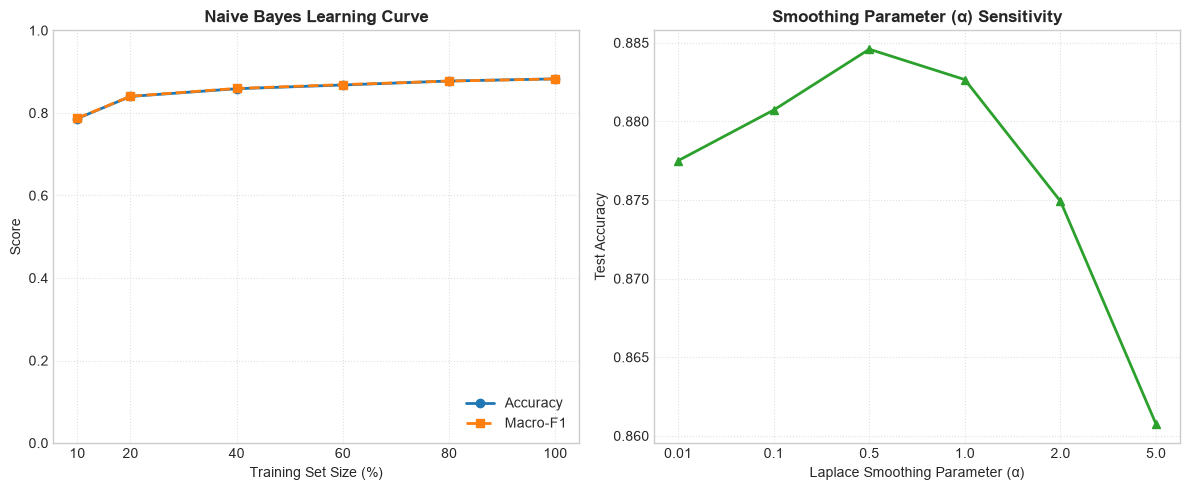

 Saved plots artifact as 'task_p2t3_plots.png'.


In [ ]:



plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Learning Curve Experiment
train_sizes = [0.10, 0.20, 0.40, 0.60, 0.80, 1.00]
accuracies_lc = []
macro_f1s_lc = []

total_train_docs = len(X_train_tok)

for frac in train_sizes:
    subset_size = int(total_train_docs * frac)
    X_sub = X_train_tok[:subset_size]
    y_sub = train_ng.target[:subset_size]
    
    # Fit Multinomial Naive Bayes from Scratch
    clf_lc = MultinomialNaiveBayesFromScratch(alpha=1.0)
    clf_lc.fit(X_sub, y_sub)
    preds = clf_lc.predict(X_test_tok)
    
    acc = accuracy_score(test_ng.target, preds)
    f1 = f1_score(test_ng.target, preds, average='macro')
    
    accuracies_lc.append(acc)
    macro_f1s_lc.append(f1)

# 2. Smoothing Parameter (Alpha) Sensitivity Experiment
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
accuracies_alpha = []

for a in alpha_values:
    clf_alpha = MultinomialNaiveBayesFromScratch(alpha=a)
    clf_alpha.fit(X_train_tok, train_ng.target)
    preds = clf_alpha.predict(X_test_tok)
    
    acc = accuracy_score(test_ng.target, preds)
    accuracies_alpha.append(acc)

# 3. Plotting Figure 1: Learning Curve
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
size_pcts = [int(f * 100) for f in train_sizes]
plt.plot(size_pcts, accuracies_lc, marker='o', linewidth=2, color='#1f77b4', label='Accuracy')
plt.plot(size_pcts, macro_f1s_lc, marker='s', linewidth=2, color='#ff7f0e', linestyle='--', label='Macro-F1')

plt.title('Naive Bayes Learning Curve', fontsize=12, fontweight='bold')
plt.xlabel('Training Set Size (%)', fontsize=10)
plt.ylabel('Score', fontsize=10)
plt.xticks(size_pcts)
plt.ylim([0.0, 1.0])
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# 4. Plotting Figure 2: Alpha Sensitivity
plt.subplot(1, 2, 2)
plt.plot([str(a) for a in alpha_values], accuracies_alpha, marker='^', linewidth=2, color='#2ca02c')

plt.title('Smoothing Parameter (α) Sensitivity', fontsize=12, fontweight='bold')
plt.xlabel('Laplace Smoothing Parameter (α)', fontsize=10)
plt.ylabel('Test Accuracy', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('task_p2t3_plots.png', dpi=300)
plt.show()

print(" Saved plots artifact as 'task_p2t3_plots.png'.")
